# Historical Basic Pitch tuning — READ SAVED OUTPUTS
The final handover baseline is onset **0.99**, frame **0.30**, minimum duration **127.7 ms**, Melodia on. Historical 0.95 comparisons below explain selection; they are not another handover version. Separate candidate-run folders are intentionally omitted.

This notebook is the original executed experiment, not the group starting point. Rerunning recreates search outputs/caches and requires explicit approval. The guard below prevents accidental Run All. Use the shared label-review notebook and individual starters instead. Original experiment cells and outputs are preserved.

In [ ]:
ALLOW_HISTORICAL_TUNING_RERUN = False
if not ALLOW_HISTORICAL_TUNING_RERUN:
    raise RuntimeError("Read the saved outputs. Historical retuning is not part of this handover; obtain approval before enabling it.")

# GTSinger: evidence-guided Basic Pitch tuning

This notebook tunes the pretrained model's **note decoder**, not its weights. Training diagnostics determine useful next candidates; validation selects among a small candidate list frozen before validation predictions. Test inference is not implemented here and remains locked. Every code cell has a specific purpose and adjacent decision rationale.

The existing 100-song sample, annotations, splits, EDA notebook and original manifests remain unchanged. Source integrity checks may hash test files; test audio is never decoded for inference and test references are never scored. All experiment artifacts live under `basic_pitch_runs/tuning_001/`.

## Start here: what this experiment actually measures

**Basic Pitch listens to singing and writes down musical notes: their pitch, start time and end time. We compare these predictions with GTSinger's supplied note labels. We are not scoring the singer, lyrics, or how pleasant the audio sounds.**

The pretrained neural network was **not retrained**. We tuned the **decoder**: the rules that turn the model's signals into a list of notes. Think of adjusting how cautious someone is when writing down what they heard, rather than teaching them to hear better.

### Read the results first

These are results on **20 validation songs / 160 excerpts**, not the untouched final test set.

| Metric | Default | Onset 0.95 | Selected: onset 0.99 | Plain meaning |
|---|---:|---:|---:|---|
| Precision | 0.1522 | 0.2813 | **0.2830** | Of the predicted notes, how many matched the labels? |
| Recall | 0.2510 | 0.2693 | **0.2694** | Of the labelled notes, how many were successfully matched? |
| Main F1: pitch + start | 0.1855 | 0.2717 | **0.2726** | Balance between finding notes and avoiding unmatched predictions |
| Stricter F1: pitch + start + end | 0.0813 | 0.1598 | **0.1602** | Also requires acceptable note endings |

**The main improvement is precision: the output becomes more trustworthy, while the number of labelled notes successfully recovered improves only a little.** F1 of 0.2726 is NOT “27.26% of the melody is correct.” It is an event-matching score, not a listening-quality percentage. Onset threshold 0.99 likewise does NOT mean 99% accuracy or a calibrated 99% probability.

### What counts as a match?

For the main score, a prediction must have the right **pitch** (within half a semitone) AND start within **0.05 seconds** of the label. For integer MIDI notes, the pitch condition effectively requires the same musical note. A correct pitch that starts too late still fails. A correct pitch and start can pass even if the note ends too late.

The stricter score also checks the end: its tolerance is **20% of the reference duration or 0.05 seconds, whichever is larger**. Matches are one-to-one: one long prediction cannot match several labelled notes.

- **Precision:** matched predictions / all predictions. Unmatched predictions can be extra notes, wrong pitches, fragments or badly timed notes.
- **Recall:** matched references / all references. A missed match does not necessarily mean the melody was wholly absent; its timing may have failed.
- **F1:** `2 × precision × recall / (precision + recall)`, with zero used when there are no matches. It rewards doing both jobs well.
- **Song-macro:** pool excerpt counts within each song, calculate that song's score, then average songs equally. This prevents songs with many excerpts from dominating. Precision, recall and F1 are averaged separately.
- **Micro F1**, where printed, pools counts across the entire collection instead. It gives more influence to songs with more note events; it was not used to select the winner.
- **Successful / failed** counts measure whether processing worked, NOT transcription correctness. Successful processing can still yield a low F1.
- **Elapsed time** is runtime, not accuracy. Later notebook executions reuse cached model signals, so short runtimes are not fresh full-inference benchmarks.

### Why are the scores low?

1. **Start timing matters strongly.** On the unchanged default TRAIN predictions, allowing 0.05 / 0.10 / 0.20 seconds gives F1 0.2005 / 0.3369 / 0.4879. Many more same-pitch matches become possible with wider timing windows. This supports boundary mismatch as a contributor, but wider windows can also admit accidental matches. The actual selection rule remained 0.05 seconds.
2. **There are many unmatched predictions and missed references.** Raising the onset threshold helps precision much more than recall. It cannot restore every missing note.
3. **Label boundaries can differ from an audible sustained note.** TRAIN has 1,141 adjacent same-pitch pairs across word boundaries. A model may output one held note where the labels contain two. We preserved labels because JSON alone cannot distinguish ties from genuine rearticulation. The contribution of this issue has not been quantified.
4. **Endings are difficult too.** Selected validation F1 falls from 0.2726 to 0.1602 when endings must also match.
5. **Decoder tuning has limits.** It changes how existing model signals become notes, not the network's ability to hear singing. Vibrato, slides and breathiness are plausible difficulties, but this run did not isolate their effects.

**Bottom line:** tuning helped, but transcription remains limited under this benchmark. Do not dismiss the errors as “just a strict metric,” and do not confuse strict F1 with how recognizable the MIDI sounds.

### Why three data splits?

- **Train (60 songs):** practice material used to investigate errors and develop settings; no network-weight training here.
- **Validation (20 songs):** choose among a shortlist fixed before inspecting its prediction scores.
- **Test (20 songs):** reserved for a later separately authorized final check. It was not used for inference or scoring.

The numbered sections below explain the 15 executed code cells. Their saved results are preserved; this plain-language documentation update does not rerun the experiment.


## 1. Authorize train/validation only and verify frozen inputs

The user has authorized actual BP tuning. Keep final test disabled, restrict all inference inputs to train/validation, and compare every protected file against the existing EDA baseline before starting. A failure is a blocker, not permission to repair or resample.

### Plain-language walkthrough: Check the files and keep test locked

**Question:** Are we using the same frozen dataset?

**What the code does:** Checks saved file fingerprints, loads only training/validation inputs and disables test inference.

**How to read its output:** All 12,230 protected files were unchanged; 534 training and 160 validation excerpts were loaded.

**Why this cell is needed:** Without this check, changed files or accidental test use could invalidate the comparison.

In [1]:
from pathlib import Path
import sys,json,time,platform,importlib.metadata,hashlib
import numpy as np
import pandas as pd
from IPython.display import display,Markdown,Image
ROOT=next(p.resolve() for p in [Path.cwd(),Path.cwd().parent,Path.cwd()/'GTSinger_100_unique_sample'] if (p/'selected_100.csv').exists())
sys.path.insert(0,str(ROOT/'notebooks'))
import bp_experiment as exp
import bp_tuning_core as core
RUN_TRAIN_VAL=True
RUN_FINAL_TEST=False
assert RUN_TRAIN_VAL and not RUN_FINAL_TEST
OUT=exp.OUT; OUT.mkdir(parents=True,exist_ok=True)
initial_integrity=exp.frozen_check()
exp.dump('initial_integrity.json',initial_integrity)
rows=exp.inputs(); train=[r for r in rows if r['split']=='train']; val=[r for r in rows if r['split']=='val']
assert set(r['split'] for r in rows)=={'train','val'}
source=json.loads((ROOT/'hf_source_manifest.json').read_text(encoding='utf-8'))
print('Frozen verification:',initial_integrity)
print('Train recordings:',len(train),'Validation recordings:',len(val),'Test inference: LOCKED')

Frozen verification: {'passed': True, 'protected_files': 12230, 'changed_paths': []}
Train recordings: 534 Validation recordings: 160 Test inference: LOCKED


## Measured outcome and limits

The completed validation comparison selected **onset_099**. Primary song-macro note F1 rose from **0.1855** to **0.2726** (an absolute **8.72 percentage-point** gain). Onset 0.95 was nearly tied with 0.99; the small difference does not establish a uniquely superior threshold. The selected result remains modest in absolute terms.

All train/validation recordings were included, operational failures were not silently excluded, and a separate audit re-scored every validation recording/configuration pair using mir_eval's high-level metric API. Protected source files were unchanged. **Test inference was not run.**

In [2]:
model,model_path,model_sha=core.make_model()
versions={name:importlib.metadata.version(name) for name in ['basic-pitch','onnxruntime','numpy','librosa','mir_eval','numba','resampy','setuptools']}
provenance=dict(modelsha=model_sha,model_sha256=model_sha,model_path=str(model_path),versions=versions,backend='ONNX CPUExecutionProvider',threads=2,preprocessing='Basic Pitch built-in librosa mono/resample 22050Hz; no trim/denoise/pitch shift')
exp.dump('environment.json',dict(python=sys.version,executable=sys.executable,platform=platform.platform(),**provenance))
requirements=sorted({d.metadata['Name']+'=='+d.version for d in importlib.metadata.distributions() if d.metadata.get('Name')})
(OUT/'requirements-lock.txt').write_text('\n'.join(requirements)+'\n',encoding='utf-8')
protocol=dict(primary='song_macro_onset_pitch_f1',onset_tolerance_seconds=.05,pitch_tolerance_cents=50,offset_ratio=.2,offset_min_tolerance_seconds=.05,reference='JSON note_start/note_end aligned seconds; pitched note>0; preserve annotation boundaries',aggregation='sum TP/ref/estimated counts across excerpts in each song, compute song F1, average songs',secondary='song_macro_offset_aware_f1',selection='at most two training-selected challengers plus unchanged default; select highest validation primary F1 only if gain over default >=0.005, otherwise default; ties prefer default then lower training-chosen complexity/order; report paired song bootstrap uncertainty',failures='no missing-recording rankings; operational failures stop; empty estimates receive zero F1 when references nonempty',test='no reference parsing, inference, scoring, or selection',source_revision=source['revision'])
exp.dump('evaluation_protocol.json',protocol)
print(json.dumps(dict(versions=versions,model_sha256=model_sha,protocol=protocol),indent=2))

C:\Users\dtpz2\Documents\Daphne documents\projects\datamining\.venv-basicpitch\lib\site-packages\resampy\filters.py:50: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


{
  "versions": {
    "basic-pitch": "0.4.0",
    "onnxruntime": "1.23.2",
    "numpy": "2.2.6",
    "librosa": "0.11.0",
    "mir_eval": "0.8.2",
    "numba": "0.68.0",
    "resampy": "0.4.2",
    "setuptools": "80.10.2"
  },
  "model_sha256": "2c3c1d144bfa61ad236e92e169c13535c880469a12a047d4e73451f2c059a0ec",
  "protocol": {
    "primary": "song_macro_onset_pitch_f1",
    "onset_tolerance_seconds": 0.05,
    "pitch_tolerance_cents": 50,
    "offset_ratio": 0.2,
    "offset_min_tolerance_seconds": 0.05,
    "reference": "JSON note_start/note_end aligned seconds; pitched note>0; preserve annotation boundaries",
    "aggregation": "sum TP/ref/estimated counts across excerpts in each song, compute song F1, average songs",
    "secondary": "song_macro_offset_aware_f1",
    "selection": "at most two training-selected challengers plus unchanged default; select highest validation primary F1 only if gain over default >=0.005, otherwise default; ties prefer default then lower training-chosen c

## 3. Audit and convert training note references

The JSON contains silence/breath markers and performance-aligned note_start/note_end. note_dur often disagrees with aligned boundaries, so it is not used to reconstruct offsets. Preserve adjacent same-pitch events rather than silently merging score/word boundaries; this is explicitly an as-annotated benchmark. Any malformed reference stops the experiment. The independent training audit found only sub-millisecond endpoint rounding (at most 0.5 ms); allow a fixed 1 ms bounds tolerance without changing timestamps. No positive-pitch duplicates, overlaps or malformed arrays were found. This audit uses training references only.

### Plain-language walkthrough: Check the answer sheet

**Question:** Are the dataset note labels usable?

**What the code does:** Reads aligned note_start/note_end times, excludes pitch-zero breaths/rests from the reference list and preserves separate labelled notes.

**How to read its output:** TRAIN contains 8,040 pitched notes. No blocking reference-format issues were found. Up to 1 ms endpoint tolerance handles rounding without shifting labels.

**Why this cell is needed:** Incorrect reference conversion would make all scores misleading. Breaths are not removed from the audio; only from the pitched answer list.

In [3]:
refs_train,audit_train=exp.references(train)
exp.dump('reference_train_audit.json',audit_train)
exp.dump('reference_notes_train.json',refs_train)
print(json.dumps(audit_train,indent=2))
if audit_train['issues']: raise RuntimeError('Reference issues must be reviewed before model tuning')
if not all(refs_train.values()): raise RuntimeError('Empty-reference recordings require an explicit reviewed policy')
reference_rows=[dict(recording_id=rid,onset_seconds=e[0],offset_seconds=e[1],midi_pitch=e[2]) for rid,events in refs_train.items() for e in events]
pd.DataFrame(reference_rows).to_csv(OUT/'reference_notes_train.csv',index=False)
print('Rest/breath markers are excluded from pitched references, not removed from audio.')

{
  "recordings": 534,
  "pitched_notes": 8040,
  "counters": {
    "annotation_notes": 9669,
    "notated_duration_disagrees_gt_1ms": 7941,
    "rest_or_breath_events": 1629
  },
  "same_pitch_adjacent_boundaries": 1141,
  "issues": [],
  "parser_policy": "as-annotated note_start/end seconds, pitch>0 only; preserve repeated notes/ties as separate annotation events; no score-duration reconstruction, no per-recording alignment optimization, no source modification",
  "shorter_than_default_fraction": 0.07475124378109453,
  "median_note_seconds": 0.3989999999999999
}
Rest/breath markers are excluded from pitched references, not removed from audio.


## 4. Prove model execution and cached decoding agree

Start with one deterministic training recording per language—not an accuracy-selected subset. Run a real default prediction on the first recording, cache the actual activations, and verify that cached decoding produces the same note events. The low-level decoder takes frames whereas predict() takes milliseconds; the helper uses the installed implementation’s exact conversion. Activation arrays are copied before decoding because Basic Pitch may mutate them.

### Plain-language walkthrough: Prove saved model signals give the same answer

**Question:** Can we speed up tuning without changing predictions?

**What the code does:** Uses one training excerpt per language for a small check; compares a normal prediction against decoding saved model signals for one excerpt.

**How to read its output:** The checked direct and cached predictions agree. The small smoke-test score is NOT the full benchmark.

**Why this cell is needed:** Caching avoids repeated neural inference. This verifies the shortcut before using it broadly; it does not prove transcription accuracy.

In [4]:
smoke=[]; seen=set()
for row in sorted(train,key=lambda r:(r['language'],r['recording_id'])):
    if row['language'] not in seen: smoke.append(row); seen.add(row['language'])
smoke_cache=exp.run_cache(smoke,model,provenance)
from basic_pitch.inference import predict
r=smoke[0]
direct_arrays,direct_midi,direct_notes=predict(ROOT/r['audio_path'],model)
with np.load(smoke_cache[r['recording_id']]['npz_path'],allow_pickle=False) as f: cached_arrays={k:f[k] for k in f.files}
assert all(np.allclose(direct_arrays[k],cached_arrays[k],rtol=1e-5,atol=1e-6) for k in direct_arrays)
default=exp.config('default')
cached_midi,cached_notes=core.decode(cached_arrays,{k:v for k,v in default.items() if k!='name'})
assert len(cached_notes)==len(direct_notes)
assert np.allclose(np.asarray([x[:4] for x in cached_notes]),np.asarray([x[:4] for x in direct_notes]),rtol=1e-5,atol=1e-6)
exp.dump('cache_equivalence.json',dict(passed=True,recording_id=r['recording_id'],notes=len(direct_notes),conversion='int(np.round(minimum_note_length/1000*(AUDIO_SAMPLE_RATE/FFT_HOP)))'))
smoke_results=exp.evaluate(smoke,refs_train,smoke_cache,[default],'smoke')
print('Actual direct prediction and cached decoding agree.')

Activation cache: 9 / 9 elapsed 0.2 s


Predicting MIDI for C:\Users\dtpz2\Documents\Daphne documents\projects\datamining\GTSinger_100_unique_sample\source_files\Chinese\ZH-Tenor-1\Mixed_Voice_and_Falsetto\崇拜\Mixed_Voice_Group\0007.wav...


smoke default {"song_macro_f1": 0.17198174485858442, "song_macro_offset_f1": 0.07400732977886455, "song_macro_precision": 0.14414013364181338, "song_macro_recall": 0.22314390402625697, "micro_f1": 0.15774647887323945, "songs": 9, "recordings": 9, "config": "default", "elapsed_seconds": 0.14854899999954796, "attempted": 9, "successful": 9, "failed": 0}


Actual direct prediction and cached decoding agree.


## 5. Inspect training alignment before scaling

Overlay reference and predicted note events for the smoke recordings. This reveals gross timing/pitch errors that a scalar F1 could hide. No reference-derived time shift or octave correction is applied: those would make the benchmark artificially easier. These plots concern training only.

### Plain-language walkthrough: Look at the mistakes

**Question:** Where do predictions disagree with labels?

**What the code does:** Plots blue reference notes and orange predictions: horizontal position is time, vertical position is pitch.

**How to read its output:** Sideways differences suggest timing mismatch; height differences indicate pitch differences. Multiple orange pieces against one blue note suggest fragmentation; one orange line across several blue notes suggests merging.

**Why this cell is needed:** Plots expose errors that one average hides. These are illustrative training excerpts, not a complete error census.

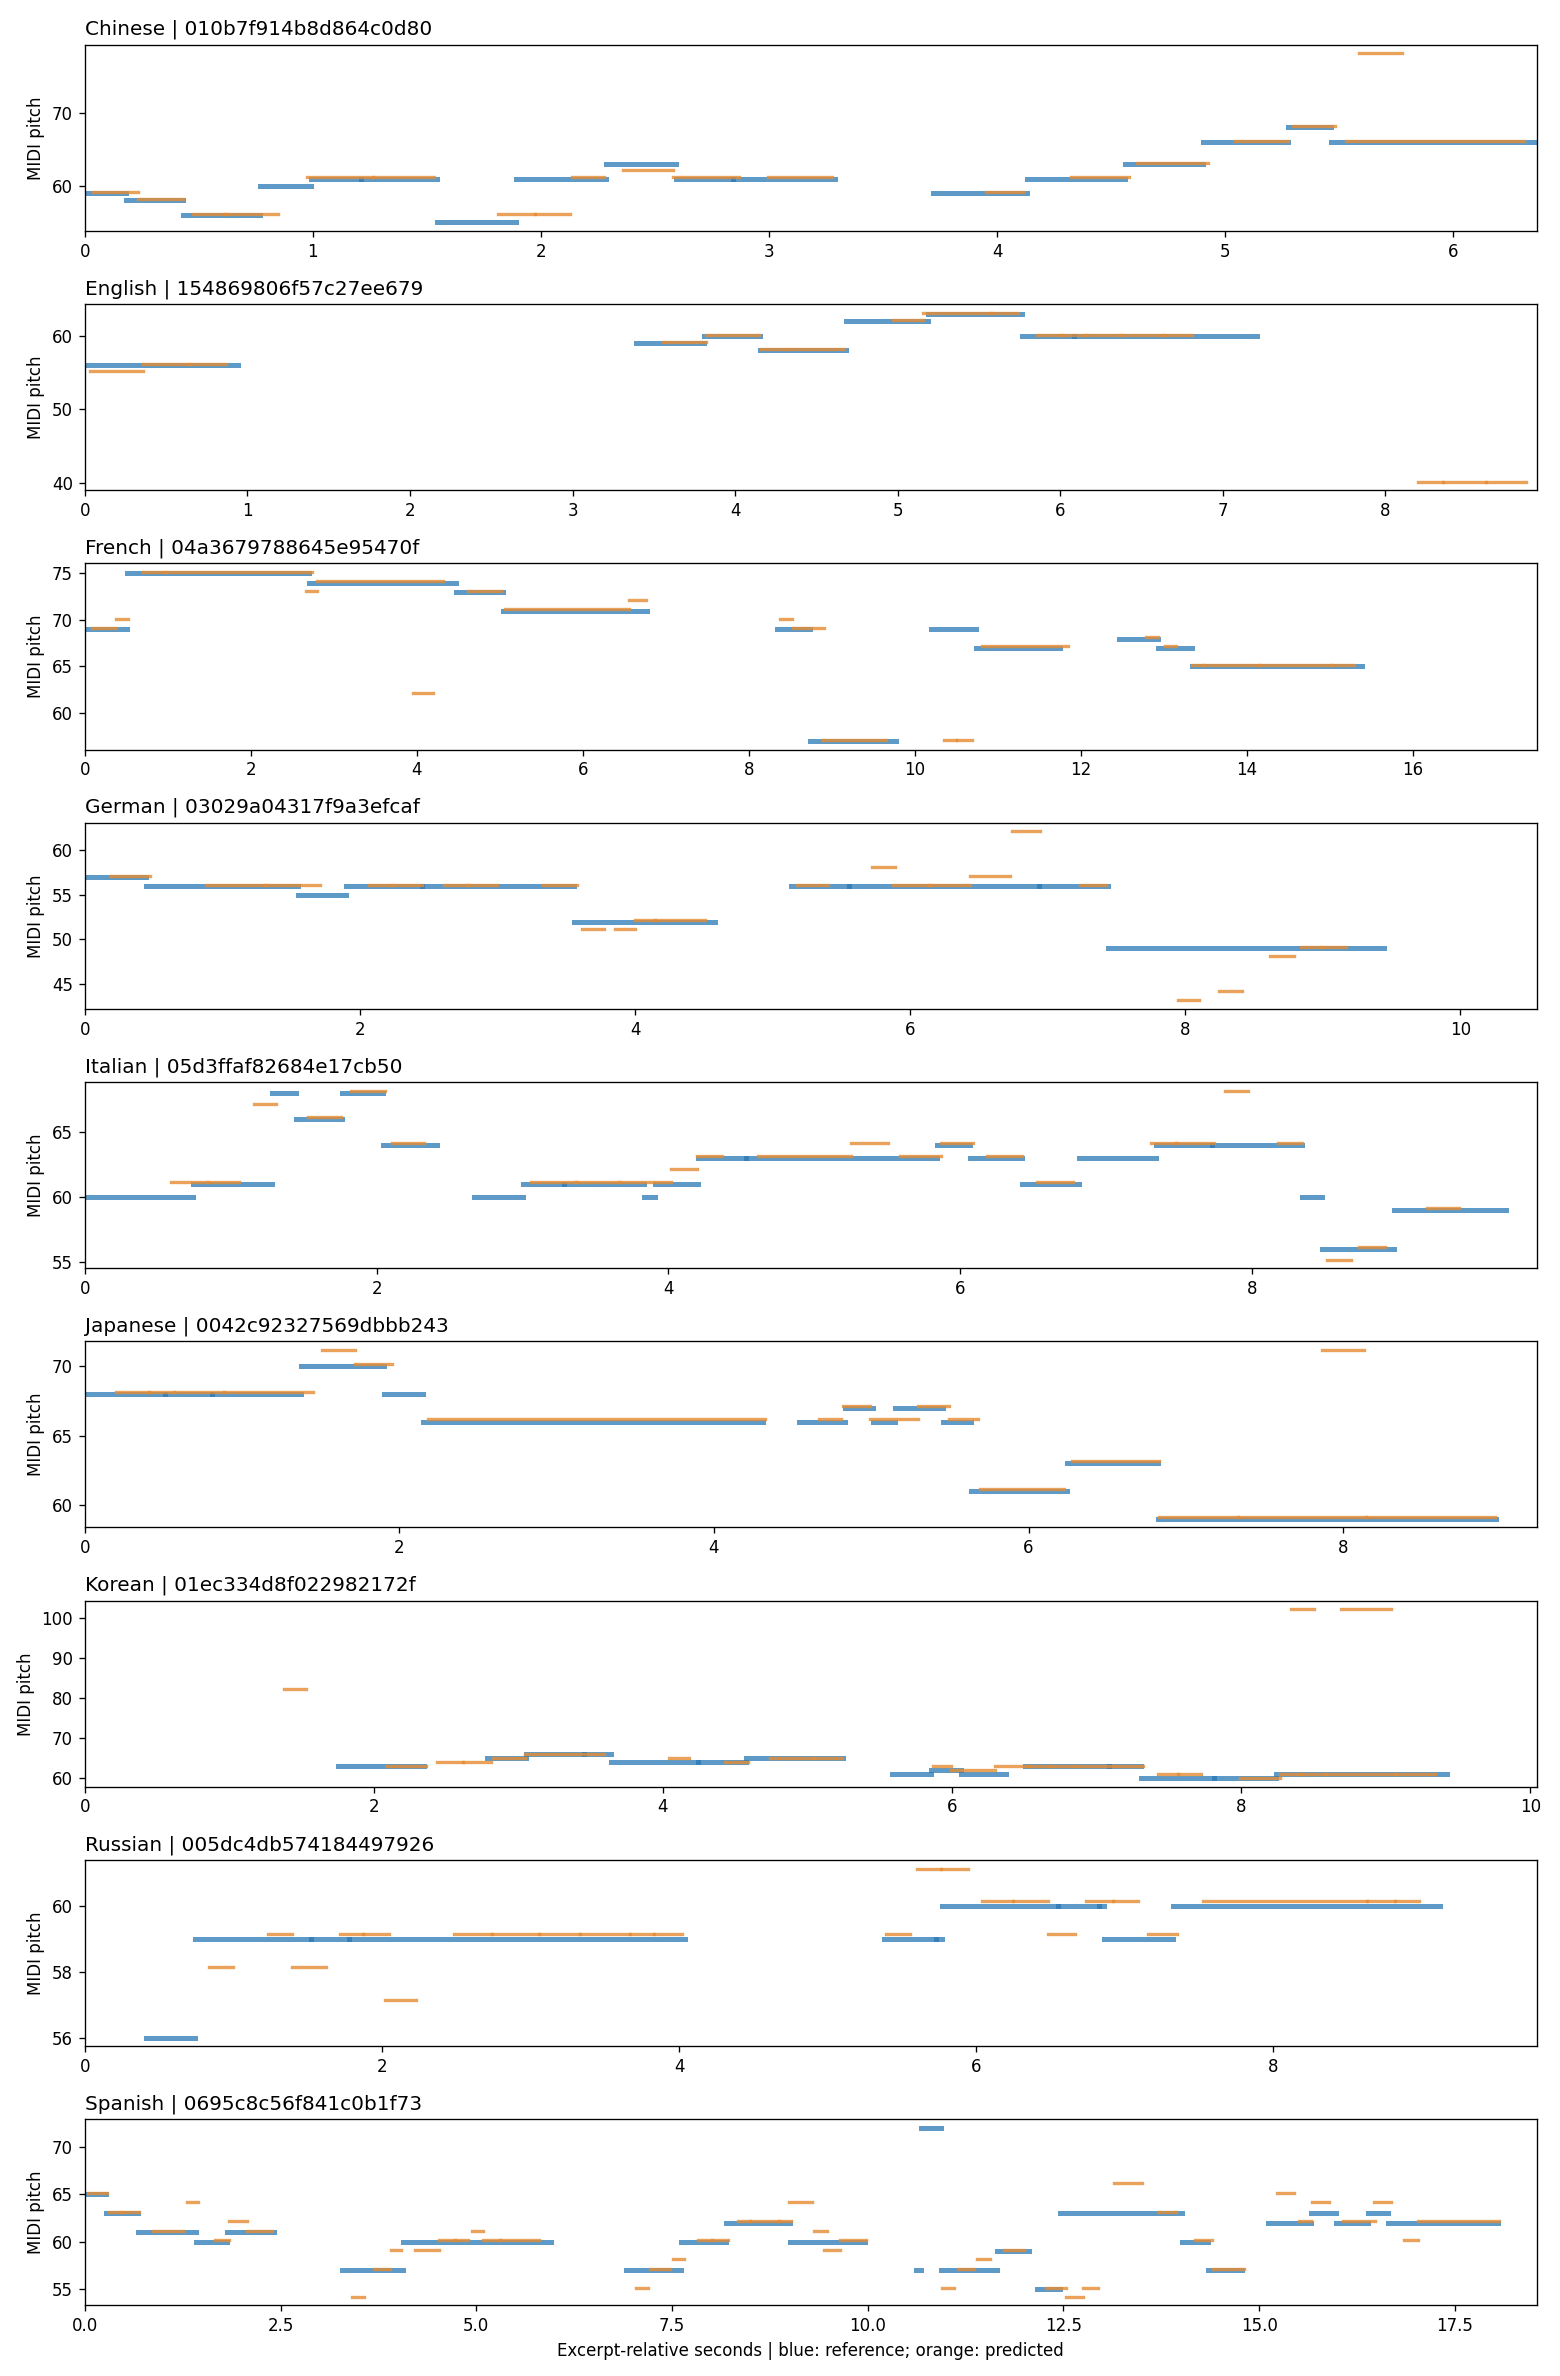

In [5]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
fig,axes=plt.subplots(len(smoke),1,figsize=(13,2.2*len(smoke)),squeeze=False)
for ax,row in zip(axes[:,0],smoke):
    ref=refs_train[row['recording_id']]; pred=smoke_results['default']['predictions'][row['recording_id']]
    for start,end,pitch in ref: ax.plot([start,end],[pitch,pitch],color='#2878B5',linewidth=3,alpha=.75)
    for start,end,pitch,amplitude in pred: ax.plot([start,end],[pitch+.15,pitch+.15],color='#E58B32',linewidth=2,alpha=.8)
    ax.set_title(row['language']+' | '+row['recording_id'],loc='left'); ax.set_ylabel('MIDI pitch'); ax.set_xlim(0,float(row['duration_seconds_if_validated']))
axes[-1,0].set_xlabel('Excerpt-relative seconds | blue: reference; orange: predicted')
fig.tight_layout(); plot=OUT/'smoke_alignment.png'; fig.savefig(plot,dpi=120); plt.close(fig)
display(Image(filename=str(plot)))

## 6. Cache training activations and measure the default baseline

Cache expensive neural inference once per training recording, keyed by audio/model/runtime provenance. Score the unmodified default over every training excerpt and pool counts within each song. These real precision/recall and short-note diagnostics will determine the next candidates; validation has not yet been scored.

### Plain-language walkthrough: Measure the unmodified baseline

**Question:** What happens before tuning?

**What the code does:** Caches every training excerpt and scores the default decoder across all 60 training songs.

**How to read its output:** Training precision 0.1679, recall 0.2636, F1 0.2005. Many predictions and reference events remain unmatched.

**Why this cell is needed:** We need a baseline to know if a change helps. Training means development data here, not weight training.

In [6]:
train_cache=exp.run_cache(train,model,provenance)
train_baseline=exp.evaluate(train,refs_train,train_cache,[default],'train_baseline')
display(pd.DataFrame([train_baseline['default']['summary']]))
exp.dump('training_baseline_decision_inputs.json',dict(baseline=train_baseline['default']['summary'],short_note_fraction=audit_train['shorter_than_default_fraction'],reference_adjacent_same_pitch_boundaries=audit_train['same_pitch_adjacent_boundaries']))
print('Training baseline ready. Candidate refinement is based on these diagnostics, not test data.')

Activation cache: 25 / 534 elapsed 0.4 s


Activation cache: 50 / 534 elapsed 0.8 s


Activation cache: 75 / 534 elapsed 1.2 s


Activation cache: 100 / 534 elapsed 1.6 s


Activation cache: 125 / 534 elapsed 2.1 s


Activation cache: 150 / 534 elapsed 2.7 s


... (18 outputs left out)

train_baseline default 450 / 534


train_baseline default {"song_macro_f1": 0.20049518118207016, "song_macro_offset_f1": 0.09413887048622956, "song_macro_precision": 0.1679470415569879, "song_macro_recall": 0.263579295888653, "micro_f1": 0.2002318571759796, "songs": 60, "recordings": 534, "config": "default", "elapsed_seconds": 8.39193030000024, "attempted": 534, "successful": 534, "failed": 0}


,song_macro_f1,song_macro_offset_f1,song_macro_precision,song_macro_recall,micro_f1,songs,recordings,config,elapsed_seconds,attempted,successful,failed
0,0.200495,0.094139,0.167947,0.263579,0.200232,60,534,default,8.39193,534,534,0


Training baseline ready. Candidate refinement is based on these diagnostics, not test data.


## 7. Diagnose why the baseline misses reference events

The complete training baseline has song-macro F1 **0.2005**, precision **0.1679** and recall **0.2636**. The smoke plots show much of the pitch sequence is tracked but with extra notes and displaced/merged boundaries. Before adjusting thresholds, quantify how much training matching changes at wider onset tolerances. This is diagnostic only: the 50 ms primary criterion remains frozen; no timing shift, label merging or relaxed validation metric is introduced.

### Plain-language walkthrough: Check sensitivity to start timing

**Question:** Is it finding pitches near the right time but outside our strict window?

**What the code does:** Scores the same default training predictions with three timing windows; does not move notes or change the official selection metric.

**How to read its output:** F1 is 0.2005 at 0.05 s, 0.3369 at 0.10 s and 0.4879 at 0.20 s. More matches become possible with looser timing.

**Why this cell is needed:** This diagnoses sensitivity, not a legitimate way to inflate the reported result. Median signed error uses only matched notes and is not a universal correction for all predictions.

In [7]:
from mir_eval.transcription import match_notes
from librosa import midi_to_hz
diagnostic=[]
base_predictions=train_baseline['default']['predictions']
for tolerance in [.05,.10,.20]:
    metrics=[]; signed_errors=[]
    for r in train:
        ref=np.asarray(refs_train[r['recording_id']],dtype=float)
        pred=np.asarray(base_predictions[r['recording_id']],dtype=float)
        matches=match_notes(ref[:,:2],midi_to_hz(ref[:,2]),pred[:,:2],midi_to_hz(pred[:,2]),onset_tolerance=tolerance,pitch_tolerance=50,offset_ratio=None) if len(pred) else []
        signed_errors.extend(float(pred[j,0]-ref[i,0]) for i,j in matches)
        metrics.append(dict(sample_id=r['sample_id'],recording_id=r['recording_id'],ref_count=len(ref),est_count=len(pred),tp_onset=len(matches),tp_offset=0))
    _,summary=core.aggregate(metrics)
    diagnostic.append(dict(onset_tolerance_seconds=tolerance,song_macro_f1=summary['song_macro_f1'],median_signed_onset_error_seconds=float(np.median(signed_errors)),matched_notes=len(signed_errors)))
diagnostic=pd.DataFrame(diagnostic)
diagnostic.to_csv(OUT/'training_timing_diagnostic.csv',index=False)
display(diagnostic)
print('These training-only sensitivity scores are NOT used as the selection metric.')

,onset_tolerance_seconds,song_macro_f1,median_signed_onset_error_seconds,matched_notes
0,0.05,0.200495,0.009128,2159
1,0.10,0.336943,0.031158,3562
2,0.20,0.487903,0.066962,5120


These training-only sensitivity scores are NOT used as the selection metric.


## 8. Test targeted decoder changes on training only

Precision is lower than recall, so extra predicted events are a problem; timing diagnostics also warrant testing onset sensitivity in both directions. Use interpretable one-factor changes instead of an arbitrary large grid: lower/higher onset threshold, higher frame threshold, disabling the extra melodia recovery pass, and shorter minimum notes. The short-note variant is justified because **7.48%** of training reference notes are shorter than the default cutoff. Every candidate is scored on all training songs. Validation remains unopened for inference; the next refinement depends on these measured results.

### Plain-language walkthrough: Try interpretable changes

**Question:** Which direction might help?

**What the code does:** Tests lower/higher onset thresholds, stronger frame evidence, no extra Melodia recovery and shorter allowed notes, all on train.

**How to read its output:** Higher onset threshold helps most; stronger frames help slightly alone. Lower onset threshold, shorter notes and disabling recovery hurt overall F1.

**Why this cell is needed:** Onset threshold controls evidence for starting a note; frame threshold controls evidence for active pitch; minimum length removes short events. Melodia is an extra recovery pass. The name earlier_onsets means lower threshold, not guaranteed earlier timing.

In [8]:
train_candidates=[exp.config('earlier_onsets',onset=.3),exp.config('stricter_onsets',onset=.7),exp.config('stronger_frames',frame=.5),exp.config('no_melodia',melodia=False),exp.config('short_notes',length=63.85)]
exp.dump('train_search_candidates.json',train_candidates)
train_search=exp.evaluate(train,refs_train,train_cache,train_candidates,'train_search')
train_results={**train_baseline,**train_search}
train_comparison=pd.DataFrame([v['summary'] for v in train_results.values()]).sort_values('song_macro_f1',ascending=False)
train_comparison.to_csv(OUT/'train_comparison.csv',index=False)
display(train_comparison[['config','song_macro_f1','song_macro_precision','song_macro_recall','song_macro_offset_f1','successful','failed']])
print('Next: inspect these training results and refine only directions supported by evidence.')

train_search earlier_onsets 150 / 534


train_search earlier_onsets 300 / 534


train_search earlier_onsets 450 / 534


train_search earlier_onsets {"song_macro_f1": 0.1526486648907694, "song_macro_offset_f1": 0.043256831654036446, "song_macro_precision": 0.11233183469868488, "song_macro_recall": 0.25644448019497446, "micro_f1": 0.15279543720710576, "songs": 60, "recordings": 534, "config": "earlier_onsets", "elapsed_seconds": 9.28113359999952, "attempted": 534, "successful": 534, "failed": 0}


train_search stricter_onsets 150 / 534


train_search stricter_onsets 300 / 534


... (12 outputs left out)

train_search short_notes 450 / 534


train_search short_notes {"song_macro_f1": 0.18896067972968114, "song_macro_offset_f1": 0.07206810243877775, "song_macro_precision": 0.13793394286057292, "song_macro_recall": 0.32707630682874134, "micro_f1": 0.18210169491525424, "songs": 60, "recordings": 534, "config": "short_notes", "elapsed_seconds": 8.33859719999964, "attempted": 534, "successful": 534, "failed": 0}


,config,song_macro_f1,song_macro_precision,song_macro_recall,song_macro_offset_f1,successful,failed
2,stricter_onsets,0.237090,0.213509,0.276167,0.133535,534,0
3,stronger_frames,0.209069,0.189815,0.245405,0.101656,534,0
0,default,0.200495,0.167947,0.263579,0.094139,534,0
4,no_melodia,0.197386,0.169847,0.248849,0.093610,534,0
5,short_notes,0.188961,0.137934,0.327076,0.072068,534,0
1,earlier_onsets,0.152649,0.112332,0.256444,0.043257,534,0


Next: inspect these training results and refine only directions supported by evidence.


## 9. Refine only the promising training directions

The training results support a narrower direction: onset 0.7 improves macro F1 from **0.2005** to **0.2371**; raising the frame threshold alone reaches **0.2091**. Shorter notes and disabling melodia both hurt. Therefore keep melodia enabled, try onset 0.9, test whether stronger frames combine usefully with stricter onsets, and test a 200 ms minimum to suppress short fragments. This is not an exhaustive grid: the choices follow measured training evidence. The onset-tolerance diagnostic improved with relaxed matching, but I retain the preregistered 50 ms metric rather than improving scores by redefining correctness.

### Plain-language walkthrough: Follow the promising direction

**Question:** Does stricter onset detection keep helping?

**What the code does:** Tests onset 0.9 and combinations with frame threshold or minimum length.

**How to read its output:** Onset 0.9 reaches training F1 0.2620; stronger frames combined with it hurt. Longer notes do not improve the corresponding onset-0.7 comparison.

**Why this cell is needed:** Follow measured evidence rather than changing everything at random. Failed combinations do not prove that every possible combination is bad.

In [9]:
refinements=[exp.config('onset_090',onset=.9),exp.config('onset_070_frame_050',onset=.7,frame=.5),exp.config('onset_090_frame_050',onset=.9,frame=.5),exp.config('onset_070_length_200',onset=.7,length=200)]
exp.dump('training_refinement_candidates.json',refinements)
refinement_results=exp.evaluate(train,refs_train,train_cache,refinements,'train_refinement')
train_results.update(refinement_results)
all_configs=[default]+train_candidates+refinements
train_comparison=pd.DataFrame([v['summary'] for v in train_results.values()]).sort_values('song_macro_f1',ascending=False)
train_comparison.to_csv(OUT/'train_comparison.csv',index=False)
display(train_comparison[['config','song_macro_f1','song_macro_precision','song_macro_recall','song_macro_offset_f1']])


train_refinement onset_090 150 / 534


train_refinement onset_090 300 / 534


train_refinement onset_090 450 / 534


train_refinement onset_090 {"song_macro_f1": 0.2619653557103085, "song_macro_offset_f1": 0.15527409910479525, "song_macro_precision": 0.26228362561178825, "song_macro_recall": 0.2667946818841171, "micro_f1": 0.26519541363580323, "songs": 60, "recordings": 534, "config": "onset_090", "elapsed_seconds": 7.903713499999867, "attempted": 534, "successful": 534, "failed": 0}


train_refinement onset_070_frame_050 150 / 534


train_refinement onset_070_frame_050 300 / 534


... (7 outputs left out)

train_refinement onset_070_length_200 300 / 534


train_refinement onset_070_length_200 450 / 534


train_refinement onset_070_length_200 {"song_macro_f1": 0.2352176131920885, "song_macro_offset_f1": 0.1339299491100581, "song_macro_precision": 0.24138890315886694, "song_macro_recall": 0.2379143427294236, "micro_f1": 0.23839009287925697, "songs": 60, "recordings": 534, "config": "onset_070_length_200", "elapsed_seconds": 7.823042099998929, "attempted": 534, "successful": 534, "failed": 0}


,config,song_macro_f1,song_macro_precision,song_macro_recall,song_macro_offset_f1
6,onset_090,0.261965,0.262284,0.266795,0.155274
2,stricter_onsets,0.237090,0.213509,0.276167,0.133535
9,onset_070_length_200,0.235218,0.241389,0.237914,0.133930
7,onset_070_frame_050,0.234741,0.231769,0.245560,0.132673
8,onset_090_frame_050,0.224973,0.247914,0.210740,0.130800
3,stronger_frames,0.209069,0.189815,0.245405,0.101656
0,default,0.200495,0.167947,0.263579,0.094139
4,no_melodia,0.197386,0.169847,0.248849,0.093610
5,short_notes,0.188961,0.137934,0.327076,0.072068
1,earlier_onsets,0.152649,0.112332,0.256444,0.043257


## 10. Check the promising onset neighborhood, then stop broadening the search

Onset 0.9 is now the best training setting: F1 **0.2620**, versus **0.2005** for default. Combining stronger frames with it reduces F1 to **0.2250**; longer notes also did not improve the corresponding onset-0.7 setting. Keep the other parameters at default. Check 0.85, 0.95 and 0.99 to see whether the gain is local or continues toward the upper end. This small, training-only neighborhood replaces a large multidimensional sweep; it does not change references, metric tolerances or test access.

### Plain-language walkthrough: Check nearby thresholds and stop expanding

**Question:** Are gains levelling off?

**What the code does:** Tests onset thresholds 0.85, 0.95 and 0.99 while other settings remain default.

**How to read its output:** Training F1: 0.85 → 0.2497; 0.90 → 0.2620; 0.95 → 0.2636; 0.99 → 0.2628. The upper end is a plateau.

**Why this cell is needed:** Tiny gains do not justify an endless search. This is a sensible stopping point for this limited run, not proof of a global optimum.

In [10]:
local_candidates=[exp.config('onset_085',onset=.85),exp.config('onset_095',onset=.95),exp.config('onset_099',onset=.99)]
local_results=exp.evaluate(train,refs_train,train_cache,local_candidates,'train_local_refinement')
train_results.update(local_results); all_configs+=local_candidates
train_comparison=pd.DataFrame([v['summary'] for v in train_results.values()]).sort_values('song_macro_f1',ascending=False)
train_comparison.to_csv(OUT/'train_comparison.csv',index=False)
exp.dump('all_training_configs.json',all_configs)
display(train_comparison[['config','song_macro_f1','song_macro_precision','song_macro_recall','song_macro_offset_f1']])


train_local_refinement onset_085 150 / 534


train_local_refinement onset_085 300 / 534


train_local_refinement onset_085 450 / 534


train_local_refinement onset_085 {"song_macro_f1": 0.24967167134973897, "song_macro_offset_f1": 0.14715242919525517, "song_macro_precision": 0.24126965809138892, "song_macro_recall": 0.2642745085081337, "micro_f1": 0.2522746071133168, "songs": 60, "recordings": 534, "config": "onset_085", "elapsed_seconds": 7.9847416000011435, "attempted": 534, "successful": 534, "failed": 0}


train_local_refinement onset_095 150 / 534


train_local_refinement onset_095 300 / 534


... (3 outputs left out)

train_local_refinement onset_099 300 / 534


train_local_refinement onset_099 450 / 534


train_local_refinement onset_099 {"song_macro_f1": 0.26275846642410683, "song_macro_offset_f1": 0.15386648702425776, "song_macro_precision": 0.27330092213557544, "song_macro_recall": 0.2582440522033118, "micro_f1": 0.26521100683138604, "songs": 60, "recordings": 534, "config": "onset_099", "elapsed_seconds": 7.937211999998908, "attempted": 534, "successful": 534, "failed": 0}


,config,song_macro_f1,song_macro_precision,song_macro_recall,song_macro_offset_f1
11,onset_095,0.263628,0.273221,0.259820,0.154553
12,onset_099,0.262758,0.273301,0.258244,0.153866
6,onset_090,0.261965,0.262284,0.266795,0.155274
10,onset_085,0.249672,0.241270,0.264275,0.147152
2,stricter_onsets,0.237090,0.213509,0.276167,0.133535
9,onset_070_length_200,0.235218,0.241389,0.237914,0.133930
7,onset_070_frame_050,0.234741,0.231769,0.245560,0.132673
8,onset_090_frame_050,0.224973,0.247914,0.210740,0.130800
3,stronger_frames,0.209069,0.189815,0.245405,0.101656
0,default,0.200495,0.167947,0.263579,0.094139


## Consolidated results: all decoder settings and combinations tested

**The other decoder settings were changed during experimentation, but returned to their defaults in the final configuration. Only onset differs from default in the selected result.** This table consolidates the completed training search immediately after the final local-refinement cell. Every configuration below was evaluated on all 534 training excerpts across 60 songs.

| Configuration | Onset | Frame | Minimum duration (ms) | Melodia recovery | Training F1  Validation F1 |
|---|---:|---:|---:|:---:|---:|---:|
| `default` | 0.50 | 0.30 | 127.7 | On | 0.2005  0.1855 |
| `earlier_onsets` | 0.30 | 0.30 | 127.7 | On | 0.1526  Not evaluated |
| `stricter_onsets` | 0.70 | 0.30 | 127.7 | On | 0.2371  Not evaluated |
| `stronger_frames` | 0.50 | 0.50 | 127.7 | On | 0.2091  Not evaluated |
| `no_melodia` | 0.50 | 0.30 | 127.7 | Off | 0.1974  Not evaluated |
| `short_notes` | 0.50 | 0.30 | 63.85 | On | 0.1890  Not evaluated |
| `onset_090` | 0.90 | 0.30 | 127.7 | On | 0.2620  Not evaluated |
| `onset_070_frame_050` | 0.70 | 0.50 | 127.7 | On | 0.2347  Not evaluated |
| `onset_090_frame_050` | 0.90 | 0.50 | 127.7 | On | 0.2250  Not evaluated |
| `onset_070_length_200` | 0.70 | 0.30 | 200 | On | 0.2352  Not evaluated |
| `onset_085` | 0.85 | 0.30 | 127.7 | On | 0.2497  Not evaluated |
| `onset_095` | 0.95 | 0.30 | 127.7 | On | 0.2636  0.2717 |
| **`onset_099` — selected** | 0.99 | 0.30 | 127.7 | On | 0.2628  0.2726 |

**How to choose the winner:** training F1 determined the shortlist; **validation F1 determined the final selection**. Onset 0.95 was higher on training (0.2636), but onset 0.99 narrowly won on validation (0.2726 versus 0.2717). Validation values here are a retrospective summary of the later validation cells, not information used to develop the training candidates. Only default, 0.95 and 0.99 were evaluated on validation; “Not evaluated” is not zero.


### What did the combination tests actually establish?

**Raising frame threshold helped at default onset, but hurt at the higher onsets tested.** Everything except frame threshold is held constant within each row below.

| Onset threshold | F1 with frame 0.30 | F1 with frame 0.50 | Interpretation |
|---|---:|---:|---|
| 0.50 | 0.2005 | 0.2091 | Slight improvement |
| 0.70 | 0.2371 | 0.2347 | Slight deterioration |
| 0.90 | 0.2620 | 0.2250 | Larger deterioration |

This is direct evidence of **interaction**: changing a setting can help in one combination and hurt in another.

**Longer minimum notes did not help at onset 0.70.** With frame threshold 0.30, minimum duration 127.7 ms gave F1 0.2371, while 200 ms gave 0.2352.

**Shorter notes and disabling recovery were tested only at default onset 0.50.** Allowing 63.85 ms notes gave 0.1890; disabling Melodia gave 0.1974; default gave 0.2005. These results do not establish what those changes would do at onset 0.95 or 0.99.

### Why were the other defaults retained?

The tested combinations did not improve on the promising onset-only settings, so the search focused on onset and retained frame 0.30, minimum duration 127.7 ms and Melodia enabled. This was a reasonable limited-search decision, **not proof that the remaining defaults are optimal**.

### What was not tested?

- Onset 0.95 or 0.99 with other frame thresholds, durations or Melodia disabled.
- Joint changes to onset, frame threshold and minimum duration together.
- Frame thresholds other than 0.30 and 0.50.

A bounded joint search could therefore still find a better combination. Its outcome is unknown; no extra tuning was performed for this explanation.

### Retrospective validation outcome — shown here for completeness

The following summarizes results produced by the later validation cells. **These results were not available when the training combinations above were developed.** The actual notebook execution freezes the shortlist before validation inference.

| Finalist | Onset | Frame | Minimum duration (ms) | Melodia recovery | Training F1 | Validation F1 |
|---|---:|---:|---:|:---:|---:|---:|
| `default` | 0.50 | 0.30 | 127.7 | On | 0.2005 | 0.1855 |
| `onset_095` | 0.95 | 0.30 | 127.7 | On | 0.2636 | 0.2717 |
| **`onset_099` — selected** | 0.99 | 0.30 | 127.7 | On | 0.2628 | 0.2726 |

**Onset 0.95 was best on training; onset 0.99 narrowly won on validation.** The final selected settings are onset **0.99**, frame **0.30**, minimum duration **127.7 ms**, and Melodia **enabled**. These are best among the evaluated finalists, not a demonstrated global optimum.

## 11. Stop training-side refinement and freeze the validation shortlist

Training F1 has plateaued: onset 0.95 gives **0.2636**, 0.99 gives **0.2628**, and 0.9 gives **0.2620**. The tiny difference at the upper end does not justify continuing to add parameters. Following the protocol fixed before scoring, take the two highest-scoring training challengers plus default. Freeze their exact parameters, model/runtime, helper code, reference policy and input manifest hashes **before** validation predictions. No candidate will be added or modified after validation results are seen.

### Plain-language walkthrough: Freeze the finalists

**Question:** Which settings are allowed into validation?

**What the code does:** Selects default and the two strongest training challengers, then saves their exact settings and provenance.

**How to read its output:** Finalists: default, onset 0.95 and onset 0.99.

**Why this cell is needed:** Freezing prevents inventing new candidates in response to validation scores. Think of submitting finalists before opening the next exam paper.

In [11]:
config_by_name={c['name']:c for c in all_configs}
ranked=train_comparison.loc[train_comparison.config!='default'].sort_values(['song_macro_f1','config'],ascending=[False,True])
finalist_names=['default']+ranked.config.head(2).tolist()
finalists=[config_by_name[name] for name in finalist_names]
lock=dict(candidates=finalists,selection_rule=protocol['selection'],model_sha256=model_sha,environment_versions=versions,protocol_sha256=exp.sha(OUT/'evaluation_protocol.json'),source_manifest_sha256={name:exp.sha(ROOT/name) for name in ['selected_100.csv','selected_recordings.csv','selected_files.csv','split_manifest.csv']},helper_sha256={name:exp.sha(ROOT/'notebooks'/name) for name in ['bp_experiment.py','bp_tuning_core.py']},training_leaderboard_scores={row.config:float(row.song_macro_f1) for row in train_comparison.itertuples()})
lock_path=OUT/'validation_candidate_lock.json'
if lock_path.exists():
    existing=json.loads(lock_path.read_text(encoding='utf-8'))
    if existing!=lock: raise RuntimeError('Validation shortlist/protocol changed; use a separately declared experiment, not this locked run.')
else: exp.dump('validation_candidate_lock.json',lock)
print('Frozen before validation inference:',finalist_names)
display(pd.DataFrame(finalists))

Frozen before validation inference: ['default', 'onset_095', 'onset_099']


,name,onset_threshold,frame_threshold,minimum_note_length,melodia_trick
0,default,0.50,0.3,127.7,True
1,onset_095,0.95,0.3,127.7,True
2,onset_099,0.99,0.3,127.7,True


## 12. Evaluate the frozen candidates on validation

Apply the already-frozen reference conversion and tolerances to validation. Stop on any malformed reference rather than excluding clips. Cache validation activations once, and evaluate the default and the two frozen challengers on exactly the same recordings. Operational failures invalidate the comparison. This is the only validation comparison phase; it does not feed another search.

### Plain-language walkthrough: Compare on different songs

**Question:** Does the improvement carry beyond the development songs?

**What the code does:** Applies the same reference and scoring rules to every validation excerpt for the three frozen settings.

**How to read its output:** Validation F1: default 0.1855, onset 0.95 at 0.2717, onset 0.99 at 0.2726. All 160 excerpts processed successfully.

**Why this cell is needed:** Both challengers beat default here; their difference is tiny. These are selection-set results, not final-test performance.

In [12]:
refs_val,audit_val=exp.references(val)
exp.dump('reference_validation_audit.json',audit_val)
exp.dump('reference_notes_val.json',refs_val)
if audit_val['issues']: raise RuntimeError('Validation reference issues: stop without changing the frozen policy')
val_cache=exp.run_cache(val,model,provenance)
val_results=exp.evaluate(val,refs_val,val_cache,finalists,'validation')
val_comparison=pd.DataFrame([v['summary'] for v in val_results.values()]).sort_values(['song_macro_f1','config'],ascending=[False,True])
val_comparison.to_csv(OUT/'validation_comparison.csv',index=False)
assert all(x['summary']['successful']==len(val) and x['summary']['failed']==0 for x in val_results.values())
display(val_comparison[['config','song_macro_f1','song_macro_offset_f1','song_macro_precision','song_macro_recall','successful','failed']])

Activation cache: 25 / 160 elapsed 4.9 s


Activation cache: 50 / 160 elapsed 10.3 s


Activation cache: 75 / 160 elapsed 16.4 s


Activation cache: 100 / 160 elapsed 23.3 s


Activation cache: 125 / 160 elapsed 30.6 s


Activation cache: 150 / 160 elapsed 35.9 s


... (4 outputs left out)

validation onset_095 {"song_macro_f1": 0.27173987311241976, "song_macro_offset_f1": 0.1597698653360625, "song_macro_precision": 0.2812500896385493, "song_macro_recall": 0.2693178657039873, "micro_f1": 0.27351485148514854, "songs": 20, "recordings": 160, "config": "onset_095", "elapsed_seconds": 2.302223299999241, "attempted": 160, "successful": 160, "failed": 0}


validation onset_099 150 / 160


validation onset_099 {"song_macro_f1": 0.27264306924988774, "song_macro_offset_f1": 0.16024855433363022, "song_macro_precision": 0.2830341217616114, "song_macro_recall": 0.2694095883675054, "micro_f1": 0.2737060041407868, "songs": 20, "recordings": 160, "config": "onset_099", "elapsed_seconds": 2.2791128999997454, "attempted": 160, "successful": 160, "failed": 0}


,config,song_macro_f1,song_macro_offset_f1,song_macro_precision,song_macro_recall,successful,failed
2,onset_099,0.272643,0.160249,0.283034,0.269410,160,0
1,onset_095,0.271740,0.159770,0.281250,0.269318,160,0
0,default,0.185471,0.081307,0.152188,0.251006,160,0


## 13. Select by the fixed rule and quantify uncertainty

Select the best validation primary score only if its absolute F1 gain over default is at least 0.005; otherwise retain default. Use a paired bootstrap over songs—not clips—to show uncertainty in the gain. These intervals are conditional on this small validation set and the selected candidates; they are not a held-out test guarantee. The offset-aware metric is reported, not substituted opportunistically for the primary metric.

### Plain-language walkthrough: Pick the winner and check uncertainty

**Question:** Which setting wins under our fixed rule?

**What the code does:** Chooses the best validation F1 if gain exceeds the predeclared minimum; repeatedly resamples songs to assess variability of gain versus default.

**How to read its output:** Onset 0.99 wins. The bootstrap describes uncertainty in improvement versus default, not proof that 0.99 reliably beats 0.95.

**Why this cell is needed:** A small validation set gives an uncertain estimate. Bootstrap resampling creates no new songs and does not remove selection bias.

In [13]:
base=val_results['default']['summary']['song_macro_f1']
best_name=val_comparison.iloc[0]['config']
gain=float(val_results[best_name]['summary']['song_macro_f1']-base)
chosen_name=best_name if gain>=.005 else 'default'
chosen_config=config_by_name[chosen_name]
base_songs=pd.DataFrame(val_results['default']['song_metrics']).set_index('sample_id')
bootstrap_rows=[]
for name in finalist_names:
    candidate=pd.DataFrame(val_results[name]['song_metrics']).set_index('sample_id').loc[base_songs.index]
    delta=candidate.f1.to_numpy()-base_songs.f1.to_numpy()
    rng=np.random.default_rng(20261010)
    estimates=np.mean(delta[rng.integers(0,len(delta),size=(2000,len(delta)))],axis=1)
    low,high=np.quantile(estimates,[.025,.975])
    bootstrap_rows.append(dict(config=name,mean_f1_gain=float(delta.mean()),ci95_low=float(low),ci95_high=float(high),songs=len(delta),bootstrap_draws=2000))
bootstrap=pd.DataFrame(bootstrap_rows)
bootstrap.to_csv(OUT/'paired_song_bootstrap.csv',index=False)
selection=dict(chosen_config=chosen_config,default_validation=val_results['default']['summary'],chosen_validation=val_results[chosen_name]['summary'],absolute_primary_gain=float(val_results[chosen_name]['summary']['song_macro_f1']-base),rule=protocol['selection'],chosen_using='validation_only_from_train_frozen_shortlist',candidate_lock_sha256=exp.sha(lock_path),test_inference_run=False,bootstrap=bootstrap_rows)
selection_path=OUT/'selected_config.json'
if selection_path.exists():
    old=json.loads(selection_path.read_text(encoding='utf-8'))
    if old['chosen_config']!=chosen_config or old['candidate_lock_sha256']!=selection['candidate_lock_sha256']:
        raise RuntimeError('Existing selected configuration cannot be silently changed')
exp.dump('selected_config.json',selection)
exp.dump('test_lock.json',dict(locked=True,final_test_authorized=False,final_test_run=False,selected_config=chosen_name,reason='Separate user approval required for once-only final evaluation'))
display(bootstrap)
print('Selected:',chosen_name,'| Absolute validation F1 gain:',selection['absolute_primary_gain'])

,config,mean_f1_gain,ci95_low,ci95_high,songs,bootstrap_draws
0,default,0.000000,0.000000,0.000000,20,2000
1,onset_095,0.086268,0.062033,0.108608,20,2000
2,onset_099,0.087172,0.063572,0.109691,20,2000


Selected: onset_099 | Absolute validation F1 gain: 0.08717157068718129


## 14. Explain subgroup behavior without further retuning

Show the selected/default comparison at song level, including language/range breakdowns and subgroup sample counts. This is diagnostic reporting only: it must not trigger new validation-driven configurations. Small groups are descriptive, not reliable evidence of singer/language-specific generalization. The reference preserves repeated-pitch annotation boundaries, so some sustained predictions are penalized as missed articulation events.

### Plain-language walkthrough: Look beyond the average

**Question:** Are improvements uneven across songs or groups?

**What the code does:** Reports language/range/singer groups and plots individual songs. In the scatter plot, above the diagonal means the selected setting is better.

**How to read its output:** Group tables describe this sample; some contain very few songs. No further settings were developed from them.

**Why this cell is needed:** A good average can hide weaker songs. Small groups do not justify claims about an entire language or singer population.

,songs,default_f1,chosen_f1,mean_gain
language,,,,
Chinese,2,0.209806,0.309719,0.099913
English,3,0.160964,0.221640,0.060676
French,2,0.177562,0.242857,0.065295
German,2,0.218711,0.344013,0.125302
Italian,3,0.167305,0.297999,0.130694
Japanese,2,0.227683,0.286620,0.058937
Korean,2,0.239347,0.250615,0.011268
Russian,2,0.143718,0.275220,0.131502
Spanish,2,0.145484,0.237929,0.092445


,songs,default_f1,chosen_f1,mean_gain
vocal_range,,,,
Alto,5,0.189183,0.287296,0.098112
Bass,3,0.129392,0.242798,0.113406
Soprano,6,0.224749,0.306807,0.082058
Tenor,6,0.171140,0.241191,0.070051


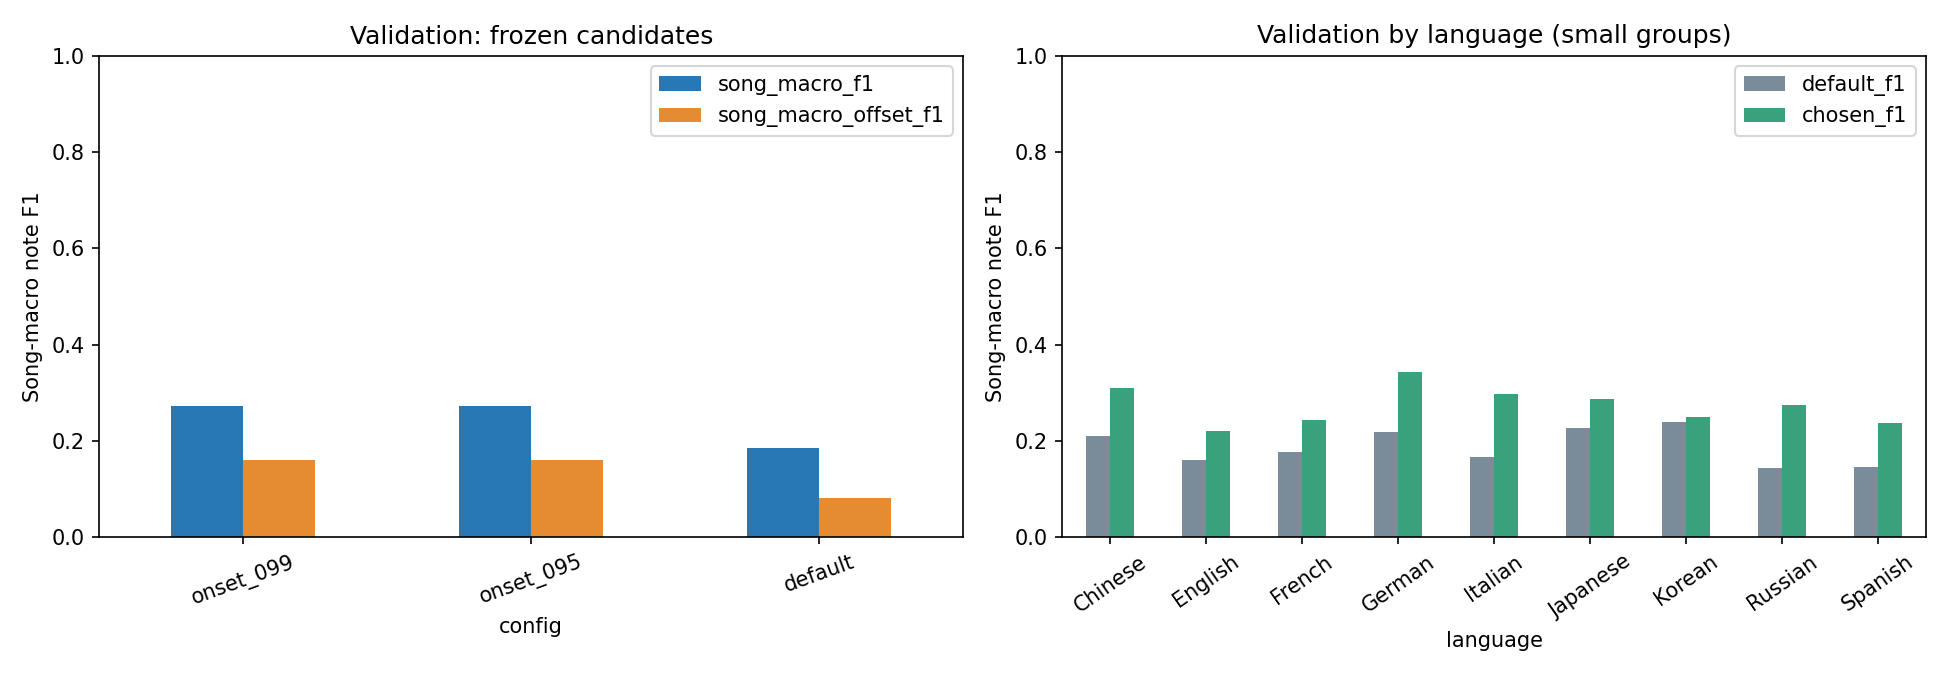

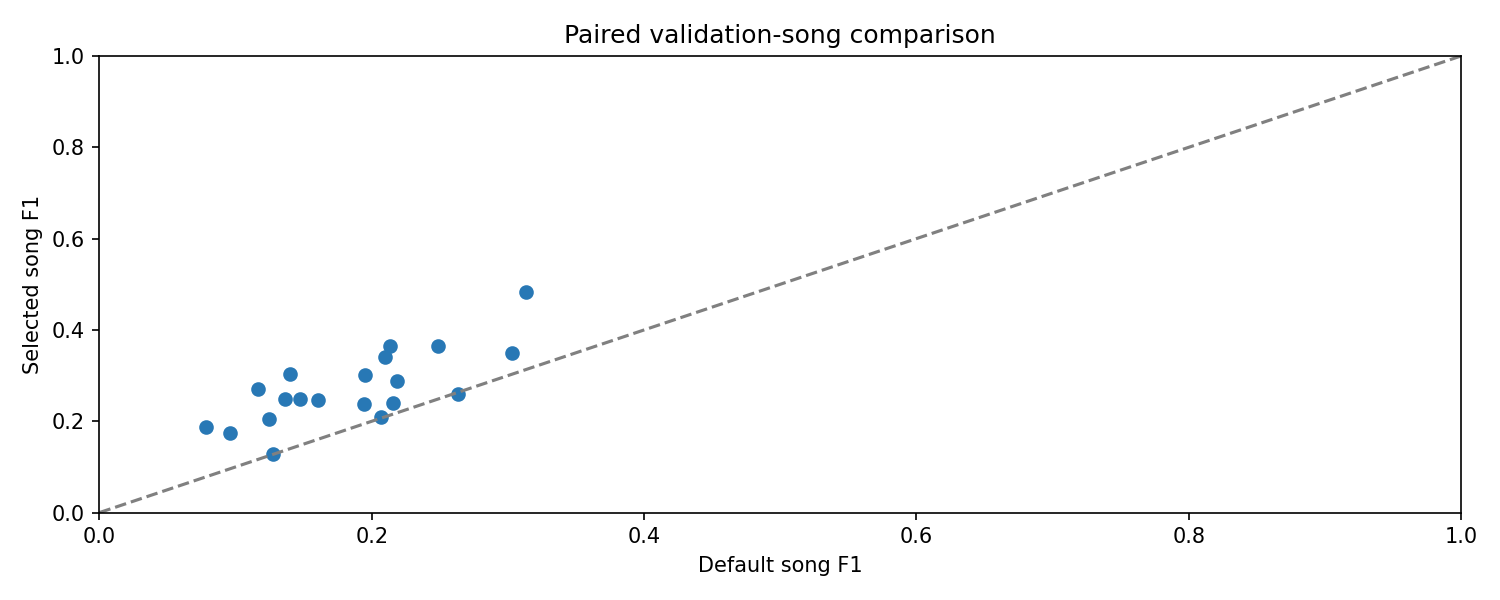

In [14]:
song_metadata=pd.DataFrame(exp.csvread('selected_100.csv'))[['sample_id','language','singer','vocal_range','technique_context','subgroup']]
base_frame=pd.DataFrame(val_results['default']['song_metrics'])[['sample_id','f1','offset_f1']].rename(columns={'f1':'default_f1','offset_f1':'default_offset_f1'})
chosen_frame=pd.DataFrame(val_results[chosen_name]['song_metrics'])[['sample_id','f1','offset_f1']].rename(columns={'f1':'chosen_f1','offset_f1':'chosen_offset_f1'})
paired=base_frame.merge(chosen_frame,on='sample_id',validate='one_to_one').merge(song_metadata,on='sample_id',validate='one_to_one')
paired['f1_gain']=paired.chosen_f1-paired.default_f1
paired.to_csv(OUT/'validation_song_comparison.csv',index=False)
for field in ['language','singer','vocal_range','technique_context','subgroup']:
    table=paired.groupby(field).agg(songs=('sample_id','size'),default_f1=('default_f1','mean'),chosen_f1=('chosen_f1','mean'),mean_gain=('f1_gain','mean'))
    table.to_csv(OUT/('validation_by_'+field+'.csv'))
    if field in ['language','vocal_range']: display(table)
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
val_comparison.set_index('config')[['song_macro_f1','song_macro_offset_f1']].plot.bar(ax=axes[0],color=['#2878B5','#E58B32'],rot=20)
axes[0].set_title('Validation: frozen candidates'); axes[0].set_ylabel('Song-macro note F1'); axes[0].set_ylim(0,1)
paired.groupby('language')[['default_f1','chosen_f1']].mean().plot.bar(ax=axes[1],color=['#7A8B99','#39A17C'],rot=35)
axes[1].set_title('Validation by language (small groups)'); axes[1].set_ylabel('Song-macro note F1'); axes[1].set_ylim(0,1)
fig.tight_layout(); plot=OUT/'validation_comparison.png'; fig.savefig(plot,dpi=150); plt.close(fig); display(Image(filename=str(plot)))
fig,ax=plt.subplots(figsize=(10,4)); ax.scatter(paired.default_f1,paired.chosen_f1,color='#2878B5'); ax.plot([0,1],[0,1],'--',color='gray'); ax.set(xlabel='Default song F1',ylabel='Selected song F1',title='Paired validation-song comparison',xlim=(0,1),ylim=(0,1)); fig.tight_layout(); plot=OUT/'validation_song_scatter.png'; fig.savefig(plot,dpi=150); plt.close(fig); display(Image(filename=str(plot)))

## 15. Export the selected train/validation predictions and finish the audit

Write selected-config MIDI and note-event CSVs using cached activations; this performs no additional neural inference and never includes test. Record the final configuration, reference-based metrics, remaining limitations and input-preservation result. Do not describe the modest absolute note scores as high transcription accuracy. Save helper source snapshots so this notebook can be reproduced with its exact experiment code.

### Plain-language walkthrough: Save usable outputs and verify preservation

**Question:** Did we finish without altering the dataset or evaluating test?

**What the code does:** Exports selected MIDI and note CSVs from cached signals, saves settings/reports and checks original file fingerprints again.

**How to read its output:** 694 train/validation excerpts exported; protected files unchanged; test inference not run.

**Why this cell is needed:** The deliverable is real predictions and an auditable experiment, not just a leaderboard. Export success is not proof of note accuracy.

In [15]:
exported=[]
for split_rows,cache in [(train,train_cache),(val,val_cache)]:
    for r in split_rows:
        with np.load(cache[r['recording_id']]['npz_path'],allow_pickle=False) as f: arrays={k:f[k] for k in f.files}
        midi,notes=core.decode(arrays,{k:v for k,v in chosen_config.items() if k!='name'})
        dest=OUT/'selected_predictions'/r['split']/r['recording_id']; dest.mkdir(parents=True,exist_ok=True)
        midi.write(str(dest/'prediction.mid'))
        events=[dict(onset_seconds=float(v[0]),offset_seconds=float(v[1]),midi_pitch=int(v[2]),amplitude=float(v[3]),pitch_bends=json.dumps(None if v[4] is None else [int(b) for b in v[4]])) for v in notes]
        pd.DataFrame(events,columns=['onset_seconds','offset_seconds','midi_pitch','amplitude','pitch_bends']).to_csv(dest/'note_events.csv',index=False)
        exported.append(dict(recording_id=r['recording_id'],split=r['split'],notes=len(notes),midi_path=str((dest/'prediction.mid').relative_to(ROOT)),notes_path=str((dest/'note_events.csv').relative_to(ROOT))))
pd.DataFrame(exported).to_csv(OUT/'selected_prediction_manifest.csv',index=False)
cache_ids={p.stem for p in (OUT/'activation_cache').glob('*.npz')}
assert cache_ids=={r['recording_id'] for r in rows}
assert not any(r['split']=='test' for r in exported)
final_integrity=exp.frozen_check(); exp.dump('final_integrity.json',final_integrity)
code_folder=OUT/'reproducibility_code'; code_folder.mkdir(exist_ok=True)
for name in ['bp_experiment.py','bp_tuning_core.py','phase_a_workflow.py','test_bp_tuning_core.py','execute_bp_notebook.py']:
    (code_folder/name).write_bytes((ROOT/'notebooks'/name).read_bytes())
final=dict(status='completed_train_validation_only',train_songs=len({r['sample_id'] for r in train}),validation_songs=len({r['sample_id'] for r in val}),training_recordings=len(train),validation_recordings=len(val),cached_recordings=len(cache_ids),training_configurations=len(all_configs),validation_configurations=len(finalists),selected_config=chosen_config,default_validation_f1=base,selected_validation_f1=val_results[chosen_name]['summary']['song_macro_f1'],selected_validation_offset_f1=val_results[chosen_name]['summary']['song_macro_offset_f1'],absolute_validation_f1_gain=selection['absolute_primary_gain'],exported_recordings=len(exported),raw_files_unchanged=final_integrity['passed'],test_inference_run=False,source_revision=source['revision'])
exp.dump('final_summary.json',final)
lines=['# Basic Pitch tuning: completed train/validation experiment','',f'Source revision: `{source["revision"]}`','',f'Selected configuration: `{chosen_name}`','', '```json',json.dumps(final,indent=2),'```','','## Decisions and evidence','', '- Used a separate Python 3.10/ONNX CPU environment; installed setuptools<81 to resolve resampy pkg_resources import.','- Preserved aligned JSON note boundaries, excluded pitch-zero rest/breath entries, and allowed only sub-millisecond annotation rounding. No label merging or time-shift optimization.','- Measured the default on all training recordings before choosing candidates.','- Lower onsets and shorter notes hurt training F1; stricter onsets helped. Stronger frames/longer notes did not help when combined.','- Refined the promising onset neighborhood, observed a plateau, and stopped broadening the search.','- Froze default plus the two best training challengers before validation inference. No post-validation tuning.','- Selected by the predetermined validation primary metric; offset-aware results and paired song bootstrap are supporting diagnostics.','','## Validation results','',val_comparison[['config','song_macro_f1','song_macro_offset_f1','song_macro_precision','song_macro_recall']].to_string(index=False),'','## Paired song bootstrap','',bootstrap.to_string(index=False),'','## Limitations','', '- Absolute strict note F1 remains modest. Improvement is not evidence of high transcription accuracy.','- Literal annotation boundaries can penalize sustained notes; no automatic tie/word-boundary merging was performed.','- Training timing sensitivity suggests boundary mismatch contributes, but relaxed criteria were not used to choose the validation winner.','- Validation is small; bootstrap intervals are conditional and do not remove selection bias or replace final held-out testing.','- Singer/range/context labels and title identity retain the original dataset caveats. This is not a singer-disjoint evaluation.','- Fine-tuning model weights, per-language calibration, denoising, pitch-range filtering and final test evaluation were not performed.','','## Integrity and test lock','',json.dumps(final_integrity,indent=2),'','Test remains locked. A separate explicit approval is required after reviewing this result.','']
(OUT/'tuning_report.md').write_text('\n'.join(lines),encoding='utf-8')
(ROOT/'reports/basic_pitch_executed_tuning_summary.md').write_text('\n'.join(lines),encoding='utf-8')
print(json.dumps(final,indent=2))
print('Final test: NOT RUN. Frozen sample: UNCHANGED.')

{
  "status": "completed_train_validation_only",
  "train_songs": 60,
  "validation_songs": 20,
  "training_recordings": 534,
  "validation_recordings": 160,
  "cached_recordings": 694,
  "training_configurations": 13,
  "validation_configurations": 3,
  "selected_config": {
    "name": "onset_099",
    "onset_threshold": 0.99,
    "frame_threshold": 0.3,
    "minimum_note_length": 127.7,
    "melodia_trick": true
  },
  "default_validation_f1": 0.18547149856270645,
  "selected_validation_f1": 0.27264306924988774,
  "selected_validation_offset_f1": 0.16024855433363022,
  "absolute_validation_f1_gain": 0.08717157068718129,
  "exported_recordings": 694,
  "raw_files_unchanged": true,
  "test_inference_run": false,
  "source_revision": "4426c862beed558b7e1cb8a4dce7e8c0c83bb208"
}
Final test: NOT RUN. Frozen sample: UNCHANGED.


## Consolidated results: all decoder settings and combinations tested

**The other decoder settings were changed during experimentation, but returned to their defaults in the final configuration. Only onset differs from default in the selected result.** This table consolidates the completed training search immediately after the final local-refinement cell. Every configuration below was evaluated on all 534 training excerpts across 60 songs.

| Configuration | Onset | Frame | Minimum duration (ms) | Melodia recovery | Training F1 |
|---|---:|---:|---:|:---:|---:|
| `default` | 0.50 | 0.30 | 127.7 | On | 0.2005 |
| `earlier_onsets` | 0.30 | 0.30 | 127.7 | On | 0.1526 |
| `stricter_onsets` | 0.70 | 0.30 | 127.7 | On | 0.2371 |
| `stronger_frames` | 0.50 | 0.50 | 127.7 | On | 0.2091 |
| `no_melodia` | 0.50 | 0.30 | 127.7 | Off | 0.1974 |
| `short_notes` | 0.50 | 0.30 | 63.85 | On | 0.1890 |
| `onset_090` | 0.90 | 0.30 | 127.7 | On | 0.2620 |
| `onset_070_frame_050` | 0.70 | 0.50 | 127.7 | On | 0.2347 |
| `onset_090_frame_050` | 0.90 | 0.50 | 127.7 | On | 0.2250 |
| `onset_070_length_200` | 0.70 | 0.30 | 200 | On | 0.2352 |
| `onset_085` | 0.85 | 0.30 | 127.7 | On | 0.2497 |
| `onset_095` | 0.95 | 0.30 | 127.7 | On | 0.2636 |
| `onset_099` | 0.99 | 0.30 | 127.7 | On | 0.2628 |

### What did the combination tests actually establish?

**Raising frame threshold helped at default onset, but hurt at the higher onsets tested.** Everything except frame threshold is held constant within each row below.

| Onset threshold | F1 with frame 0.30 | F1 with frame 0.50 | Interpretation |
|---|---:|---:|---|
| 0.50 | 0.2005 | 0.2091 | Slight improvement |
| 0.70 | 0.2371 | 0.2347 | Slight deterioration |
| 0.90 | 0.2620 | 0.2250 | Larger deterioration |

This is direct evidence of **interaction**: changing a setting can help in one combination and hurt in another.

**Longer minimum notes did not help at onset 0.70.** With frame threshold 0.30, minimum duration 127.7 ms gave F1 0.2371, while 200 ms gave 0.2352.

**Shorter notes and disabling recovery were tested only at default onset 0.50.** Allowing 63.85 ms notes gave 0.1890; disabling Melodia gave 0.1974; default gave 0.2005. These results do not establish what those changes would do at onset 0.95 or 0.99.

### Retrospective validation outcome

The following summarizes results produced by the later validation cells. **These results were not available when the training combinations above were developed.** The actual notebook execution freezes the shortlist before validation inference.

| Finalist | Onset | Frame | Minimum duration (ms) | Melodia recovery | Validation F1 |
|---|---:|---:|---:|:---:|---:|
| `default` | 0.50 | 0.30 | 127.7 | On | 0.1855 |
| `onset_095` | 0.95 | 0.30 | 127.7 | On | 0.2717 |
| `onset_099` | 0.99 | 0.30 | 127.7 | On | 0.2726 |

**Onset 0.95 was best on training; onset 0.99 narrowly won on validation.** The final selected settings are onset **0.99**, frame **0.30**, minimum duration **127.7 ms**, and Melodia **enabled**. These are best among the evaluated finalists, not a demonstrated global optimum.


## Measured outcome and limits

The completed validation comparison selected **onset_099**. Primary song-macro note F1 rose from **0.1855** to **0.2726** (an absolute **8.72 percentage-point** gain). Onset 0.95 was nearly tied with 0.99; the small difference does not establish a uniquely superior threshold. The selected result remains modest in absolute terms.

All train/validation recordings were included, operational failures were not silently excluded, and a separate audit re-scored every validation recording/configuration pair using mir_eval's high-level metric API. Protected source files were unchanged. **Test inference was not run.**